# Midway Check: Reproducing and Stress-Testing "SGC ≈ GCN"
**Team:** Vladislav Osetrov, Danis Abdulov  
**Scope:** Milestone 3 (Week 12 Midway Check) — Public split reproduction, depth/degree ablations, and 100-split variance & statistical significance study on Cora, Citeseer, and Pubmed.

### External Code & Citations
* **PyTorch Geometric (`pyg-team/pytorch_geometric`, release tag `v2.6.0`):** We use `Planetoid` dataset loaders, `NormalizeFeatures`, `GCNConv`, and `SGConv` (`examples/gcn.py` starter).
* **GCN Reference (`tkipf/gcn`, commit `39a4089`, `gcn/models.py` & `gcn/train.py`; `tkipf/pygcn` `master`):** Kipf & Welling (ICLR 2017) apply L2 weight decay ($5\times 10^{-4}$) only to the first layer $W_1$ and use a 10-epoch validation loss early-stopping window.
* **SGC Reference (`Tiiiger/SGC`, commit `2c7a272`, `citation.py` & `tuning.py`):** Wu et al. (ICML 2019) precompute $\bar{X} = \hat{A}^K X$ once (`SGConv(cached=True)`) and train logistic regression with Adam ($\text{lr}=0.2$) and tuned weight decay.

In [13]:
import os
import time
import copy
import numpy as np
import pandas as pd
from scipy import stats
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torch_geometric.datasets import Planetoid
import torch_geometric.transforms as T
from torch_geometric.utils import homophily

from models import GCN, SGC, MLP

os.makedirs('figures', exist_ok=True)

# Tuned SGC weight decay values from Tiiiger/SGC (commit 2c7a272, citation.py & tuning.py)
SGC_PARAMS = {
    'Cora':     {'wd': 5e-5, 'epochs': 100},
    'CiteSeer': {'wd': 5e-3, 'epochs': 150},
    'PubMed':   {'wd': 5e-5, 'epochs': 100},
}

## 1. Load Planetoid Datasets & Compute Edge Homophily

In [14]:
datasets = {}
rows = []
for name in ['Cora', 'CiteSeer', 'PubMed']:
    ds = Planetoid(root='./data', name=name, transform=T.NormalizeFeatures())
    data = ds[0]
    datasets[name] = data
    h = homophily(data.edge_index, data.y, method='edge')
    rows.append({
        'Dataset': name, 'Nodes': data.num_nodes, 'Edges': data.num_edges // 2,
        'Features': data.num_features, 'Classes': ds.num_classes,
        'Train/Val/Test': f"{data.train_mask.sum().item()}/{data.val_mask.sum().item()}/{data.test_mask.sum().item()}",
        'Edge Homophily (h)': round(h, 3)
    })

print(pd.DataFrame(rows).to_string(index=False))

 Dataset  Nodes  Edges  Features  Classes Train/Val/Test  Edge Homophily (h)
    Cora   2708   5278      1433        7   140/500/1000               0.810
CiteSeer   3327   4552      3703        6   120/500/1000               0.736
  PubMed  19717  44324       500        3    60/500/1000               0.802


## 2. Training & Evaluation Functions
Following `tkipf/gcn` (commit `39a4089`), GCN applies L2 weight decay ($5\times 10^{-4}$) strictly to `convs[0]` (first layer $W_1$) and stops when validation loss exceeds the rolling 10-epoch mean.

In [15]:
def train_gcn_or_mlp(model, data, lr=0.01, wd=5e-4, max_epochs=200, patience=10, seed=0):
    torch.manual_seed(seed)
    model.reset_parameters()
    # Kipf & Welling (2017): L2 penalty strictly on first layer weight matrix W_1
    first_layer = model.convs[0] if hasattr(model, 'convs') else model.fc1
    other_layers = [p for n, p in model.named_parameters() if not n.startswith(('convs.0', 'fc1'))]
    optimizer = torch.optim.Adam([
        {'params': first_layer.parameters(), 'weight_decay': wd},
        {'params': other_layers, 'weight_decay': 0.0}
    ], lr=lr)

    val_losses = []
    t0 = time.perf_counter()
    for epoch in range(1, max_epochs + 1):
        model.train()
        optimizer.zero_grad()
        out = model(data.x, data.edge_index)
        loss = F.cross_entropy(out[data.train_mask], data.y[data.train_mask])
        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            val_out = model(data.x, data.edge_index)
            val_loss = F.cross_entropy(val_out[data.val_mask], data.y[data.val_mask]).item()
        val_losses.append(val_loss)
        if patience and epoch > patience and val_loss > np.mean(val_losses[-(patience + 1):-1]):
            break
    elapsed = time.perf_counter() - t0

    model.eval()
    with torch.no_grad():
        pred = model(data.x, data.edge_index).argmax(dim=-1)
        test_acc = (pred[data.test_mask] == data.y[data.test_mask]).float().mean().item() * 100
    return test_acc, elapsed


def train_sgc(model, data, lr=0.2, wd=5e-5, epochs=100, seed=0):
    torch.manual_seed(seed)
    model.reset_parameters()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)

    t0 = time.perf_counter()
    for _ in range(epochs):
        model.train()
        optimizer.zero_grad()
        out = model(data.x, data.edge_index)
        loss = F.cross_entropy(out[data.train_mask], data.y[data.train_mask])
        loss.backward()
        optimizer.step()
    elapsed = time.perf_counter() - t0

    model.eval()
    with torch.no_grad():
        pred = model(data.x, data.edge_index).argmax(dim=-1)
        test_acc = (pred[data.test_mask] == data.y[data.test_mask]).float().mean().item() * 100
    return test_acc, elapsed

## 3. Step 1: Public Split Reproduction (10 Seeds) & Figure 1 Generation

 Dataset  GCN (L=2)  SGC (K=2)         MLP  SGC (K=0) Speedup
    Cora 80.7 ± 0.8 81.0 ± 0.0 48.1 ± 14.1 59.9 ± 0.0   25.2x
CiteSeer 70.5 ± 0.7 72.3 ± 0.1  54.2 ± 2.4 61.4 ± 0.0   16.4x
  PubMed 78.3 ± 0.4 78.8 ± 0.0 63.2 ± 15.9 73.3 ± 0.0   18.1x


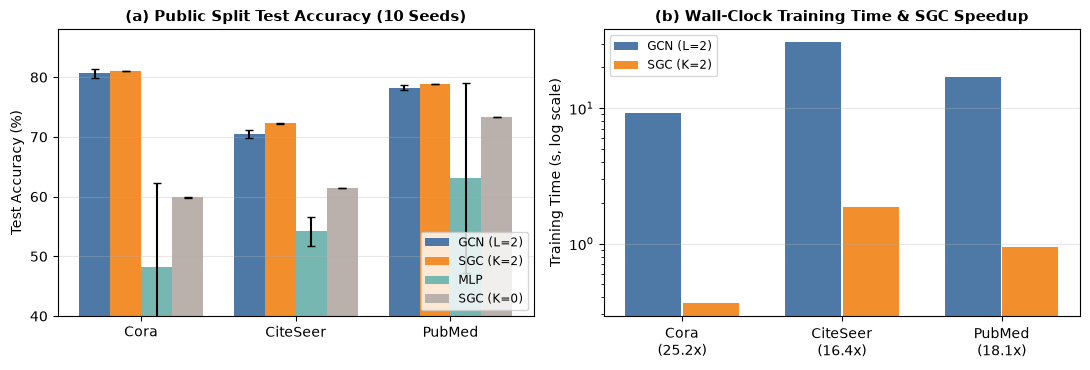

In [16]:
repro_stats = {}
repro_table = []

for name, data in datasets.items():
    num_classes = int(data.y.max().item()) + 1
    gcn  = GCN(data.num_features, num_classes, hidden_channels=16, num_layers=2, dropout=0.5)
    sgc2 = SGC(data.num_features, num_classes, K=2)
    sgc0 = SGC(data.num_features, num_classes, K=0)
    mlp  = MLP(data.num_features, num_classes, hidden_channels=16, dropout=0.5)

    cfg = SGC_PARAMS[name]
    gcn_runs  = [train_gcn_or_mlp(gcn, data, seed=s) for s in range(10)]
    sgc2_runs = [train_sgc(sgc2, data, wd=cfg['wd'], epochs=cfg['epochs'], seed=s) for s in range(10)]
    sgc0_runs = [train_sgc(sgc0, data, wd=cfg['wd'], epochs=cfg['epochs'], seed=s) for s in range(10)]
    mlp_runs  = [train_gcn_or_mlp(mlp, data, seed=s) for s in range(10)]

    repro_stats[name] = {
        'gcn_mean':  np.mean([r[0] for r in gcn_runs]),  'gcn_std':  np.std([r[0] for r in gcn_runs]),
        'sgc2_mean': np.mean([r[0] for r in sgc2_runs]), 'sgc2_std': np.std([r[0] for r in sgc2_runs]),
        'mlp_mean':  np.mean([r[0] for r in mlp_runs]),  'mlp_std':  np.std([r[0] for r in mlp_runs]),
        'sgc0_mean': np.mean([r[0] for r in sgc0_runs]), 'sgc0_std': np.std([r[0] for r in sgc0_runs]),
        'gcn_time':  np.mean([r[1] for r in gcn_runs]),
        'sgc_time':  np.mean([r[1] for r in sgc2_runs]),
    }
    st = repro_stats[name]
    repro_table.append({
        'Dataset':   name,
        'GCN (L=2)': f"{st['gcn_mean']:.1f} ± {st['gcn_std']:.1f}",
        'SGC (K=2)': f"{st['sgc2_mean']:.1f} ± {st['sgc2_std']:.1f}",
        'MLP':       f"{st['mlp_mean']:.1f} ± {st['mlp_std']:.1f}",
        'SGC (K=0)': f"{st['sgc0_mean']:.1f} ± {st['sgc0_std']:.1f}",
        'Speedup':   f"{st['gcn_time'] / st['sgc_time']:.1f}x"
    })

print(pd.DataFrame(repro_table).to_string(index=False))

# Plot Figure 1: Public Split Test Accuracy & Training Time Speedup
names = list(datasets.keys())
x = np.arange(len(names))
w = 0.2

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
ax.bar(x - 1.5*w, [repro_stats[d]['gcn_mean'] for d in names],  w, yerr=[repro_stats[d]['gcn_std'] for d in names],  capsize=3, label='GCN (L=2)', color='#4e79a7')
ax.bar(x - 0.5*w, [repro_stats[d]['sgc2_mean'] for d in names], w, yerr=[repro_stats[d]['sgc2_std'] for d in names], capsize=3, label='SGC (K=2)', color='#f28e2b')
ax.bar(x + 0.5*w, [repro_stats[d]['mlp_mean'] for d in names],  w, yerr=[repro_stats[d]['mlp_std'] for d in names],  capsize=3, label='MLP',       color='#76b7b2')
ax.bar(x + 1.5*w, [repro_stats[d]['sgc0_mean'] for d in names], w, yerr=[repro_stats[d]['sgc0_std'] for d in names], capsize=3, label='SGC (K=0)', color='#bab0ac')
ax.set_xticks(x)
ax.set_xticklabels(names)
ax.set_ylim(40, 88)
ax.set_ylabel('Test Accuracy (%)')
ax.set_title('(a) Public Split Test Accuracy (10 Seeds)', fontsize=10.5, fontweight='bold')
ax.legend(fontsize=8.5, loc='lower right')
ax.grid(axis='y', alpha=0.3)

ax = axes[1]
gcn_times = [repro_stats[d]['gcn_time'] for d in names]
sgc_times = [repro_stats[d]['sgc_time'] for d in names]
speedups  = [f"{d}\n({repro_stats[d]['gcn_time']/repro_stats[d]['sgc_time']:.1f}x)" for d in names]
ax.bar(x - 0.18, gcn_times, 0.35, label='GCN (L=2)', color='#4e79a7')
ax.bar(x + 0.18, sgc_times, 0.35, label='SGC (K=2)', color='#f28e2b')
ax.set_yscale('log')
ax.set_xticks(x)
ax.set_xticklabels(speedups)
ax.set_ylabel('Training Time (s, log scale)')
ax.set_title('(b) Wall-Clock Training Time & SGC Speedup', fontsize=10.5, fontweight='bold')
ax.legend(fontsize=8.5, loc='upper left')
ax.grid(axis='y', alpha=0.3)

fig.tight_layout()
fig.savefig('figures/fig1_reproduction.png', dpi=160, bbox_inches='tight')
plt.show()

## 4. Depth & Propagation Degree Ablation & Figure 2 Generation
Per Proposal Section *Methods*, we vary $K \in \{0, 1, 2, 4, 8\}$ for SGC and $L \in \{1, 2, 3, 4\}$ layers for GCN on each dataset.

Cora     | SGC K=[0, 1, 2, 4, 8]: [np.float64(59.8), np.float64(77.1), np.float64(81.1), np.float64(81.6), np.float64(80.6)] | GCN L=[1, 2, 3, 4]: [np.float64(76.7), np.float64(80.9), np.float64(76.0), np.float64(72.1)]
CiteSeer | SGC K=[0, 1, 2, 4, 8]: [np.float64(61.4), np.float64(71.1), np.float64(72.3), np.float64(72.5), np.float64(72.9)] | GCN L=[1, 2, 3, 4]: [np.float64(68.7), np.float64(70.2), np.float64(62.3), np.float64(46.9)]
PubMed   | SGC K=[0, 1, 2, 4, 8]: [np.float64(73.3), np.float64(76.9), np.float64(78.8), np.float64(79.5), np.float64(76.8)] | GCN L=[1, 2, 3, 4]: [np.float64(74.5), np.float64(78.4), np.float64(75.3), np.float64(73.4)]


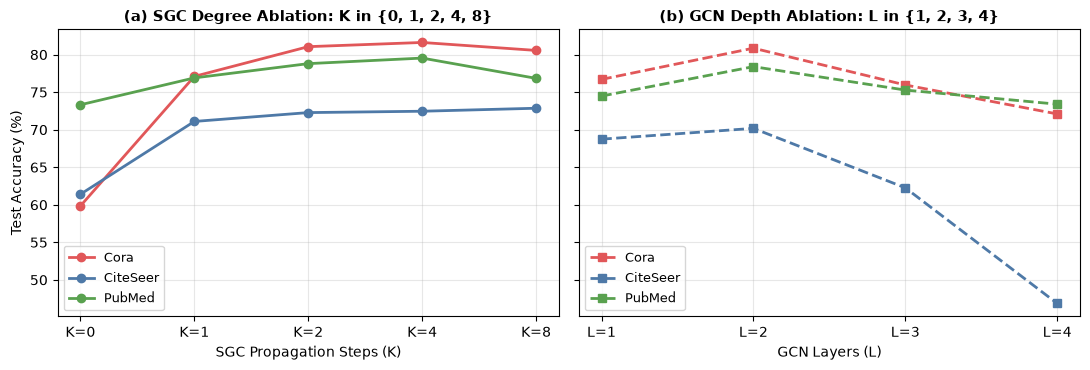

In [17]:
k_vals = [0, 1, 2, 4, 8]
l_vals = [1, 2, 3, 4]
sgc_ablation = {}
gcn_ablation = {}

for name, data in datasets.items():
    num_classes = int(data.y.max().item()) + 1
    cfg = SGC_PARAMS[name]
    sgc_ablation[name] = [
        np.mean([train_sgc(SGC(data.num_features, num_classes, K=k), data, wd=cfg['wd'], epochs=cfg['epochs'], seed=s)[0] for s in range(5)])
        for k in k_vals
    ]
    gcn_ablation[name] = [
        np.mean([train_gcn_or_mlp(GCN(data.num_features, num_classes, num_layers=l), data, seed=s)[0] for s in range(5)])
        for l in l_vals
    ]
    print(f"{name:8s} | SGC K={k_vals}: {[round(a, 1) for a in sgc_ablation[name]]} | GCN L={l_vals}: {[round(a, 1) for a in gcn_ablation[name]]}")

# Plot Figure 2: SGC Degree (K) vs. GCN Depth (L) Ablation
colors = {'Cora': '#e15759', 'CiteSeer': '#4e79a7', 'PubMed': '#59a14f'}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)

ax = axes[0]
for name in datasets:
    ax.plot(range(len(k_vals)), sgc_ablation[name], 'o-', color=colors[name], lw=2, label=name)
ax.set_xticks(range(len(k_vals)))
ax.set_xticklabels([f'K={k}' for k in k_vals])
ax.set_ylabel('Test Accuracy (%)')
ax.set_xlabel('SGC Propagation Steps (K)')
ax.set_title('(a) SGC Degree Ablation: K in {0, 1, 2, 4, 8}', fontsize=10.5, fontweight='bold')
ax.legend(fontsize=9)
ax.grid(alpha=0.3)

ax = axes[1]
for name in datasets:
    ax.plot(range(len(l_vals)), gcn_ablation[name], 's--', color=colors[name], lw=2, label=name)
ax.set_xticks(range(len(l_vals)))
ax.set_xticklabels([f'L={l}' for l in l_vals])
ax.set_xlabel('GCN Layers (L)')
ax.set_title('(b) GCN Depth Ablation: L in {1, 2, 3, 4}', fontsize=10.5, fontweight='bold')
ax.legend(fontsize=9)
ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig('figures/fig2_ablation.png', dpi=160, bbox_inches='tight')
plt.show()

## 5. Step 2: 100 Random Splits, Paired Significance & Figure 3 Generation
We generate 100 random Planetoid-sized splits (20 per class train, 500 val, 1,000 test) using `RandomNodeSplit`. Both models are evaluated on identical splits $s \in \{1, \dots, 100\}$ to compute paired differences $\delta_s = \text{acc}_{\text{GCN}}(s) - \text{acc}_{\text{SGC}}(s)$, 95% bootstrap confidence intervals, Wilcoxon signed-rank $p$-values, and law-of-total-variance decomposition.

In [ ]:
def evaluate_100_splits(name, data, n_splits=100, n_seeds=5):
    num_classes = int(data.y.max().item()) + 1
    cfg = SGC_PARAMS[name]
    gcn_mat = np.zeros((n_splits, n_seeds))
    sgc_mat = np.zeros((n_splits, n_seeds))

    for s in range(n_splits):
        split_data = copy.copy(data)
        splitter = T.RandomNodeSplit(split='train_rest', num_splits=1, num_train_per_class=20, num_val=500, num_test=1000)
        torch.manual_seed(1000 + s)
        split_data = splitter(split_data)

        gcn = GCN(data.num_features, num_classes)
        sgc = SGC(data.num_features, num_classes, K=2)
        for r in range(n_seeds):
            gcn_mat[s, r], _ = train_gcn_or_mlp(gcn, split_data, seed=r)
            sgc_mat[s, r], _ = train_sgc(sgc, split_data, wd=cfg['wd'], epochs=cfg['epochs'], seed=r)

    gcn_split_means = gcn_mat.mean(axis=1)
    sgc_split_means = sgc_mat.mean(axis=1)
    deltas = gcn_split_means - sgc_split_means

    rng = np.random.default_rng(42)
    boot_means = [rng.choice(deltas, size=n_splits, replace=True).mean() for _ in range(10000)]
    ci_low, ci_high = np.percentile(boot_means, [2.5, 97.5])
    _, p_val = stats.wilcoxon(deltas)

    # Law of total variance decomposition: Var_s(E_r[acc]) vs E_s[Var_r(acc)]
    gcn_var_split = np.var(gcn_split_means, ddof=1)
    gcn_var_init  = np.mean(np.var(gcn_mat, axis=1, ddof=1))
    gcn_split_pct = 100.0 * gcn_var_split / (gcn_var_split + gcn_var_init)

    sgc_var_split = np.var(sgc_split_means, ddof=1)
    sgc_var_init  = np.mean(np.var(sgc_mat, axis=1, ddof=1))
    sgc_split_pct = 100.0 * sgc_var_split / (sgc_var_split + sgc_var_init)

    return {
        'gcn_mean': gcn_split_means.mean(), 'gcn_std': gcn_split_means.std(ddof=1),
        'sgc_mean': sgc_split_means.mean(), 'sgc_std': sgc_split_means.std(ddof=1),
        'deltas': deltas,
        'delta_mean': deltas.mean(), 'delta_std': deltas.std(ddof=1),
        'ci_low': ci_low, 'ci_high': ci_high, 'p_val': p_val,
        'gcn_split_pct': gcn_split_pct, 'gcn_init_pct': 100.0 - gcn_split_pct,
        'sgc_split_pct': sgc_split_pct, 'sgc_init_pct': 100.0 - sgc_split_pct,
    }

split_results = {}
summary_100 = []
for name, data in datasets.items():
    res = evaluate_100_splits(name, data, n_splits=100, n_seeds=5)
    split_results[name] = res
    sig_tag = "Sig" if res['p_val'] < 0.05 else "NS"
    summary_100.append({
        'Dataset':             name,
        'GCN (100 splits)':    f"{res['gcn_mean']:.1f} ± {res['gcn_std']:.1f}%",
        'SGC (100 splits)':    f"{res['sgc_mean']:.1f} ± {res['sgc_std']:.1f}%",
        'Delta (GCN - SGC)':   f"{res['delta_mean']:+.2f} ± {res['delta_std']:.2f}%",
        '95% Bootstrap CI':    f"[{res['ci_low']:+.2f}%, {res['ci_high']:+.2f}%]",
        'Wilcoxon p':          f"{res['p_val']:.2e} ({sig_tag})" if res['p_val'] < 0.001 else f"{res['p_val']:.3f} ({sig_tag})",
        'GCN Split Var Share': f"{res['gcn_split_pct']:.1f}%"
    })

 Dataset GCN (100 splits) SGC (100 splits) Delta (GCN - SGC)   95% Bootstrap CI     Wilcoxon p GCN Split Var Share
    Cora      86.1 ± 1.2%      80.9 ± 1.6%     +5.21 ± 1.02%   [+5.01%, +5.41%] 3.90e-18 (Sig)               65.3%
CiteSeer      75.1 ± 1.3%      24.5 ± 5.8%    +50.63 ± 5.89% [+49.45%, +51.75%] 3.90e-18 (Sig)               89.2%
  PubMed      86.2 ± 1.1%      84.1 ± 1.1%     +2.06 ± 0.59%   [+1.95%, +2.18%] 3.90e-18 (Sig)               92.3%


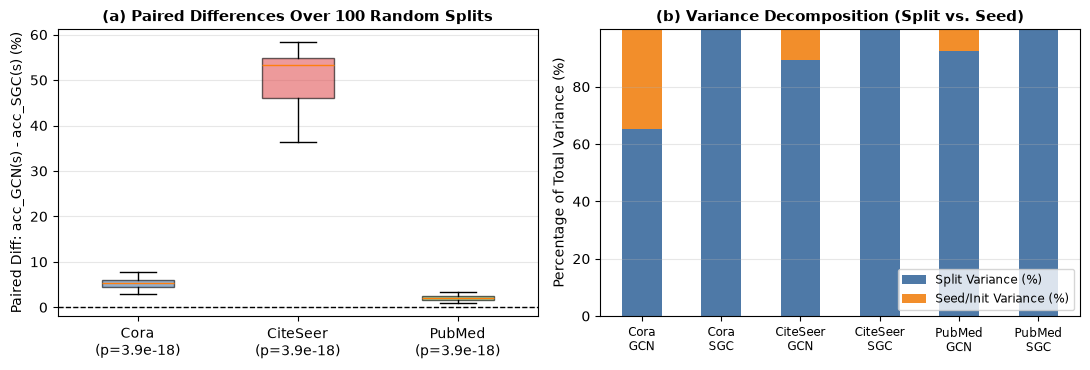

In [20]:
print(pd.DataFrame(summary_100).to_string(index=False))

# Plot Figure 3: Paired Differences Boxplot & Variance Decomposition
names = list(datasets.keys())
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

ax = axes[0]
box_data = [split_results[d]['deltas'] for d in names]
box_labels = [f"{d}\n(p={split_results[d]['p_val']:.2g})" for d in names]
bp = ax.boxplot(box_data, tick_labels=box_labels, patch_artist=True, widths=0.45)
for patch, c in zip(bp['boxes'], ['#4e79a7', '#e15759', '#59a14f']):
    patch.set_facecolor(c)
    patch.set_alpha(0.6)
ax.axhline(0, color='black', ls='--', lw=1)
ax.set_ylabel('Paired Diff: acc_GCN(s) - acc_SGC(s) (%)')
ax.set_title('(a) Paired Differences Over 100 Random Splits', fontsize=10.5, fontweight='bold')
ax.grid(axis='y', alpha=0.3)

ax = axes[1]
bar_labels, split_shares, init_shares = [], [], []
for d in names:
    bar_labels.extend([f"{d}\nGCN", f"{d}\nSGC"])
    split_shares.extend([split_results[d]['gcn_split_pct'], split_results[d]['sgc_split_pct']])
    init_shares.extend([split_results[d]['gcn_init_pct'],  split_results[d]['sgc_init_pct']])
ix = np.arange(len(bar_labels))
ax.bar(ix, split_shares, 0.5, label='Split Variance (%)', color='#4e79a7')
ax.bar(ix, init_shares,  0.5, bottom=split_shares, label='Seed/Init Variance (%)', color='#f28e2b')
ax.set_xticks(ix)
ax.set_xticklabels(bar_labels, fontsize=8.5)
ax.set_ylabel('Percentage of Total Variance (%)')
ax.set_title('(b) Variance Decomposition (Split vs. Seed)', fontsize=10.5, fontweight='bold')
ax.legend(fontsize=8.5, loc='lower right')
ax.grid(axis='y', alpha=0.3)

fig.tight_layout()
fig.savefig('figures/fig3_split_variance.png', dpi=160, bbox_inches='tight')
plt.show()